In [13]:
# Cell 1: Imports and Configuration
import os
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F  # <---- IMPORTANT: This is needed for F.adaptive_avg_pool2d
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix, classification_report
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Configuration
IMG_SIZE = 128
BATCH_SIZE = 16
EPOCHS = 30
LEARNING_RATE = 3e-4
NUM_CLASSES = 7
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Paths - UPDATE THESE
TRAIN_PATH = 'D:/Feb2026/Project/diabetic_retinopathy/fungal/train'  # Your training path
VAL_PATH = 'D:/Feb2026/Project/diabetic_retinopathy/fungal/val'      # Your validation path

Using device: cpu


In [14]:
from torchvision.datasets import ImageFolder

# Data transforms
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], 
                         [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], 
                         [0.229, 0.224, 0.225])
])

# Create datasets
train_dataset = ImageFolder(TRAIN_PATH, transform=train_transform)
val_dataset = ImageFolder(VAL_PATH, transform=val_transform)

# Access class names
print("Classes:", train_dataset.classes)

Classes: ['1. No DR signs', '2. Mild (or early) NPDR', '3. Moderate NPDR', '4. Severe NPDR', '5. Very Severe NPDR', '6. PDR', '7. Advanced PDR']


In [15]:
print("\n📊 Training class distribution:")
train_counts = np.bincount(train_labels, minlength=7)
for i in range(7):
    print(f"  Class {i} ({train_dataset.classes[i]}): {train_counts[i]} images")

print("\n📊 Validation class distribution:")
val_counts = np.bincount(val_labels, minlength=7)
for i in range(7):
    print(f"  Class {i} ({val_dataset.classes[i]}): {val_counts[i]} images")


📊 Training class distribution:
  Class 0 (1. No DR signs): 92 images
  Class 1 (2. Mild (or early) NPDR): 32 images
  Class 2 (3. Moderate NPDR): 25 images
  Class 3 (4. Severe NPDR): 58 images
  Class 4 (5. Very Severe NPDR): 36 images
  Class 5 (6. PDR): 64 images
  Class 6 (7. Advanced PDR): 38 images

📊 Validation class distribution:
  Class 0 (1. No DR signs): 9 images
  Class 1 (2. Mild (or early) NPDR): 9 images
  Class 2 (3. Moderate NPDR): 9 images
  Class 3 (4. Severe NPDR): 9 images
  Class 4 (5. Very Severe NPDR): 9 images
  Class 5 (6. PDR): 9 images
  Class 6 (7. Advanced PDR): 9 images


Using device: cpu
Number of classes: 7
Classes: ['1. No DR signs', '2. Mild (or early) NPDR', '3. Moderate NPDR', '4. Severe NPDR', '5. Very Severe NPDR', '6. PDR', '7. Advanced PDR']

 FINAL CLASS DISTRIBUTION
Training set: 345 images
Validation set: 63 images

 Training class distribution:
  Class 0 (1. No DR signs): 92 images
  Class 1 (2. Mild (or early) NPDR): 32 images
  Class 2 (3. Moderate NPDR): 25 images
  Class 3 (4. Severe NPDR): 58 images
  Class 4 (5. Very Severe NPDR): 36 images
  Class 5 (6. PDR): 64 images
  Class 6 (7. Advanced PDR): 38 images

 Validation class distribution:
  Class 0 (1. No DR signs): 9 images
  Class 1 (2. Mild (or early) NPDR): 9 images
  Class 2 (3. Moderate NPDR): 9 images
  Class 3 (4. Severe NPDR): 9 images
  Class 4 (5. Very Severe NPDR): 9 images
  Class 5 (6. PDR): 9 images
  Class 6 (7. Advanced PDR): 9 images

Train batches: 21
Validation batches: 4

Model created with 13,006,650 parameters

Class weights:
  Class 0: 0.5357
  Class 1: 1.5

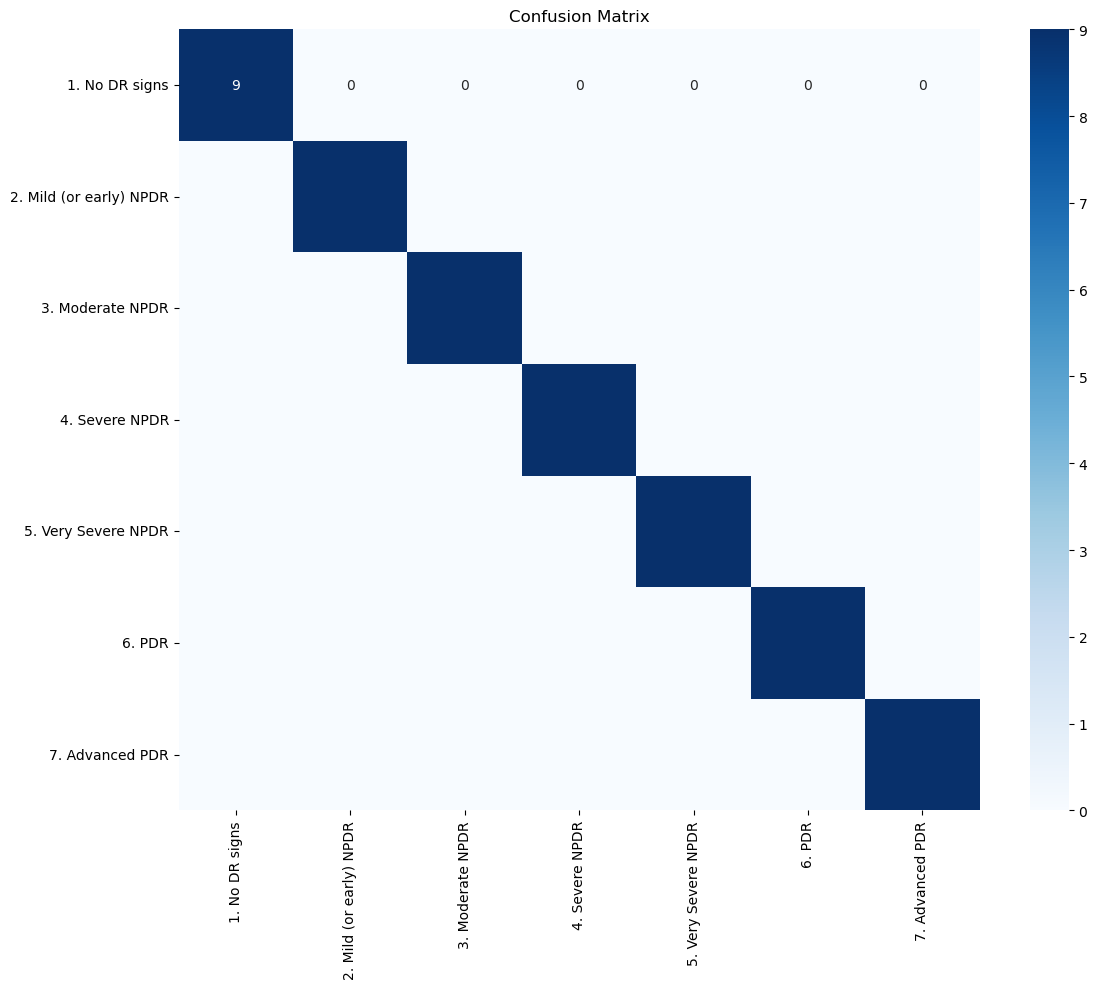

In [16]:
# ==================== IMPORTS AND CONFIGURATION ====================
import os
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import models, transforms
from torchvision.datasets import ImageFolder
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ==================== CONFIG ====================
IMG_SIZE = 128
BATCH_SIZE = 16
EPOCHS = 30
LEARNING_RATE = 3e-4
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# ==================== PATHS ====================
TRAIN_PATH = 'D:/Feb2026/Project/diabetic_retinopathy/fungal/train'
VAL_PATH = 'D:/Feb2026/Project/diabetic_retinopathy/fungal/val'

# ==================== DATA TRANSFORMS ====================
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# ==================== DATASETS ====================
train_dataset = ImageFolder(TRAIN_PATH, transform=train_transform)
val_dataset = ImageFolder(VAL_PATH, transform=val_transform)
num_classes = len(train_dataset.classes)
print(f"Number of classes: {num_classes}")
print("Classes:", train_dataset.classes)

# ==================== VERIFY CLASS DISTRIBUTION ====================
train_labels = [label for _, label in train_dataset]
val_labels = [label for _, label in val_dataset]

print("\n" + "="*70)
print(" FINAL CLASS DISTRIBUTION")
print("="*70)
print(f"Training set: {len(train_dataset)} images")
print(f"Validation set: {len(val_dataset)} images")

print("\n Training class distribution:")
train_counts = np.bincount(train_labels, minlength=num_classes)
for i in range(num_classes):
    print(f"  Class {i} ({train_dataset.classes[i]}): {train_counts[i]} images")

print("\n Validation class distribution:")
val_counts = np.bincount(val_labels, minlength=num_classes)
for i in range(num_classes):
    print(f"  Class {i} ({val_dataset.classes[i]}): {val_counts[i]} images")

# ==================== DATALOADERS ====================
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True if torch.cuda.is_available() else False,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True if torch.cuda.is_available() else False,
    drop_last=False
)

print(f"\nTrain batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

# ==================== MODEL DEFINITION ====================
class LightweightCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.cnn = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.IMAGENET1K_V1)
        self.features = self.cnn.features
        self.feat_dim = 960
        
        self.channel_attn = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(self.feat_dim, self.feat_dim // 8, 1),
            nn.ReLU(),
            nn.Conv2d(self.feat_dim // 8, self.feat_dim, 1),
            nn.Sigmoid()
        )
        self.spatial_attn = nn.Sequential(
            nn.Conv2d(2, 1, kernel_size=7, padding=3),
            nn.Sigmoid()
        )
        
    def forward(self, x):
        x = self.features(x)
        channel_weights = self.channel_attn(x)
        x = x * channel_weights
        
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        spatial_input = torch.cat([avg_out, max_out], dim=1)
        spatial_weights = self.spatial_attn(spatial_input)
        x = x * spatial_weights
        
        x = F.adaptive_avg_pool2d(x, 1)
        x = x.view(x.size(0), -1)
        return x

class LightweightViT(nn.Module):
    def __init__(self, img_size=IMG_SIZE, patch_size=16, in_channels=3, embed_dim=256, depth=8, num_heads=4):
        super().__init__()
        self.patch_embed = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.num_patches = (img_size // patch_size) ** 2
        self.pos_embed = nn.Parameter(torch.randn(1, self.num_patches, embed_dim) * 0.02)
        
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads, dim_feedforward=embed_dim * 4,
            dropout=0.2, activation='gelu', batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=depth)
        self.norm = nn.LayerNorm(embed_dim)
        
    def forward(self, x):
        x = self.patch_embed(x)
        x = x.flatten(2).transpose(1, 2)
        x = x + self.pos_embed
        x = self.transformer(x)
        x = x.mean(dim=1)
        x = self.norm(x)
        return x

class FastFusionModel(nn.Module):
    def __init__(self, num_classes=num_classes):
        super().__init__()
        self.cnn = LightweightCNN()
        self.vit = LightweightViT()
        
        self.cnn_norm = nn.LayerNorm(960)
        self.vit_norm = nn.LayerNorm(256)
        
        self.classifier = nn.Sequential(
            nn.Linear(960 + 256, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
        
    def forward(self, x):
        cnn_features = self.cnn_norm(self.cnn(x))
        vit_features = self.vit_norm(self.vit(x))
        combined = torch.cat([cnn_features, vit_features], dim=1)
        return self.classifier(combined)

# Initialize model
model = FastFusionModel().to(device)
print(f"\nModel created with {sum(p.numel() for p in model.parameters()):,} parameters")

# ==================== CLASS WEIGHTS ====================
def calculate_class_weights(dataset):
    labels = [label for _, label in dataset]
    class_counts = np.bincount(labels, minlength=num_classes)
    class_counts[class_counts == 0] = 1
    total = len(labels)
    weights = total / (class_counts * num_classes)
    weights = np.clip(weights, 0.5, 3.0)
    return torch.tensor(weights, dtype=torch.float).to(device)

class_weights = calculate_class_weights(train_dataset)
print("\nClass weights:")
for i in range(num_classes):
    print(f"  Class {i}: {class_weights[i]:.4f}")

# ==================== LOSS, OPTIMIZER, SCHEDULER ====================
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=5, T_mult=2, eta_min=1e-6)

# ==================== TRAINING LOOP ====================
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'val_f1_macro': []}
best_val_f1 = 0.0
patience_counter = 0
early_stop_patience = 10

for epoch in range(1, EPOCHS + 1):
    print(f"\nEPOCH {epoch}/{EPOCHS}")
    
    # Training
    model.train()
    train_loss, train_correct, train_total = 0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        
        train_loss += loss.item()
        _, predicted = outputs.max(1)
        train_total += labels.size(0)
        train_correct += predicted.eq(labels).sum().item()
    
    train_acc = 100. * train_correct / train_total
    avg_train_loss = train_loss / len(train_loader)
    
    # Validation
    model.eval()
    val_loss, val_correct, val_total = 0, 0, 0
    val_preds, val_labels_list = [], []
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()
            val_preds.extend(predicted.cpu().numpy())
            val_labels_list.extend(labels.cpu().numpy())
    
    val_acc = 100. * val_correct / val_total
    avg_val_loss = val_loss / len(val_loader)
    val_f1_macro = f1_score(val_labels_list, val_preds, average='macro', zero_division=0)
    scheduler.step()
    
    # Save history
    history['train_loss'].append(avg_train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(avg_val_loss)
    history['val_acc'].append(val_acc)
    history['val_f1_macro'].append(val_f1_macro)
    
    print(f"Train Loss: {avg_train_loss:.4f} | Train Acc: {train_acc:.2f}%")
    print(f"Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.2f}% | Val F1 Macro: {val_f1_macro:.4f}")
    
    if val_f1_macro > best_val_f1:
        best_val_f1 = val_f1_macro
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1_macro': val_f1_macro,
            'val_acc': val_acc
        }, 'best_model_7class.pth')
        patience_counter = 0
        print("Saved best model!")
    else:
        patience_counter += 1
    
    if patience_counter >= early_stop_patience:
        print(f"Early stopping at epoch {epoch}")
        break

print(f"\nBest validation F1 Macro: {best_val_f1:.4f}")

# ==================== FINAL EVALUATION ====================
checkpoint = torch.load('best_model_7class.pth')
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=train_dataset.classes, zero_division=0))

# Confusion Matrix
plt.figure(figsize=(12, 10))
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=train_dataset.classes,
            yticklabels=train_dataset.classes)
plt.title('Confusion Matrix')
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()

In [20]:
# ==================== IMAGE PREDICTION FUNCTION ====================
from PIL import Image

def predict_image(image_path, model, class_names):
    model.eval()
    
    # Same transform as validation
    transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ])
    
    image = Image.open(image_path).convert('RGB')
    input_tensor = transform(image).unsqueeze(0).to(device)
    
    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = torch.softmax(outputs, dim=1)
        confidence, predicted_class = torch.max(probabilities, 1)
    
    predicted_label = class_names[predicted_class.item()]
    confidence_score = confidence.item() * 100
    
    print(f"\nPrediction Result")
    print(f"Image: {image_path}")
    print(f"Predicted Class: {predicted_label}")
    print(f"Confidence: {confidence_score:.2f}%")
    
    return predicted_label, confidence_score

In [22]:
test_image_path = "D:/Feb2026/Project/diabetic_retinopathy/373.jpg"
predict_image(test_image_path, model, train_dataset.classes)


Prediction Result
Image: D:/Feb2026/Project/diabetic_retinopathy/373.jpg
Predicted Class: 4. Severe NPDR
Confidence: 98.56%


('4. Severe NPDR', 98.56173396110535)

In [18]:
model = FastFusionModel(num_classes=num_classes).to(device)
checkpoint = torch.load('best_model_7class.pth')
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

FastFusionModel(
  (cnn): LightweightCNN(
    (cnn): MobileNetV3(
      (features): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): Hardswish()
        )
        (1): InvertedResidual(
          (block): Sequential(
            (0): Conv2dNormActivation(
              (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
              (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
              (2): ReLU(inplace=True)
            )
            (1): Conv2dNormActivation(
              (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
              (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
            )
          )
        )
        (2): InvertedResidu


 FINAL MODEL EVALUATION
 Best Model Loaded (Val F1: 1.0000)

 Classification Report:
                         precision    recall  f1-score   support

         1. No DR signs       1.00      1.00      1.00         9
2. Mild (or early) NPDR       1.00      1.00      1.00         9
       3. Moderate NPDR       1.00      1.00      1.00         9
         4. Severe NPDR       1.00      1.00      1.00         9
    5. Very Severe NPDR       1.00      1.00      1.00         9
                 6. PDR       1.00      1.00      1.00         9
        7. Advanced PDR       1.00      1.00      1.00         9

               accuracy                           1.00        63
              macro avg       1.00      1.00      1.00        63
           weighted avg       1.00      1.00      1.00        63



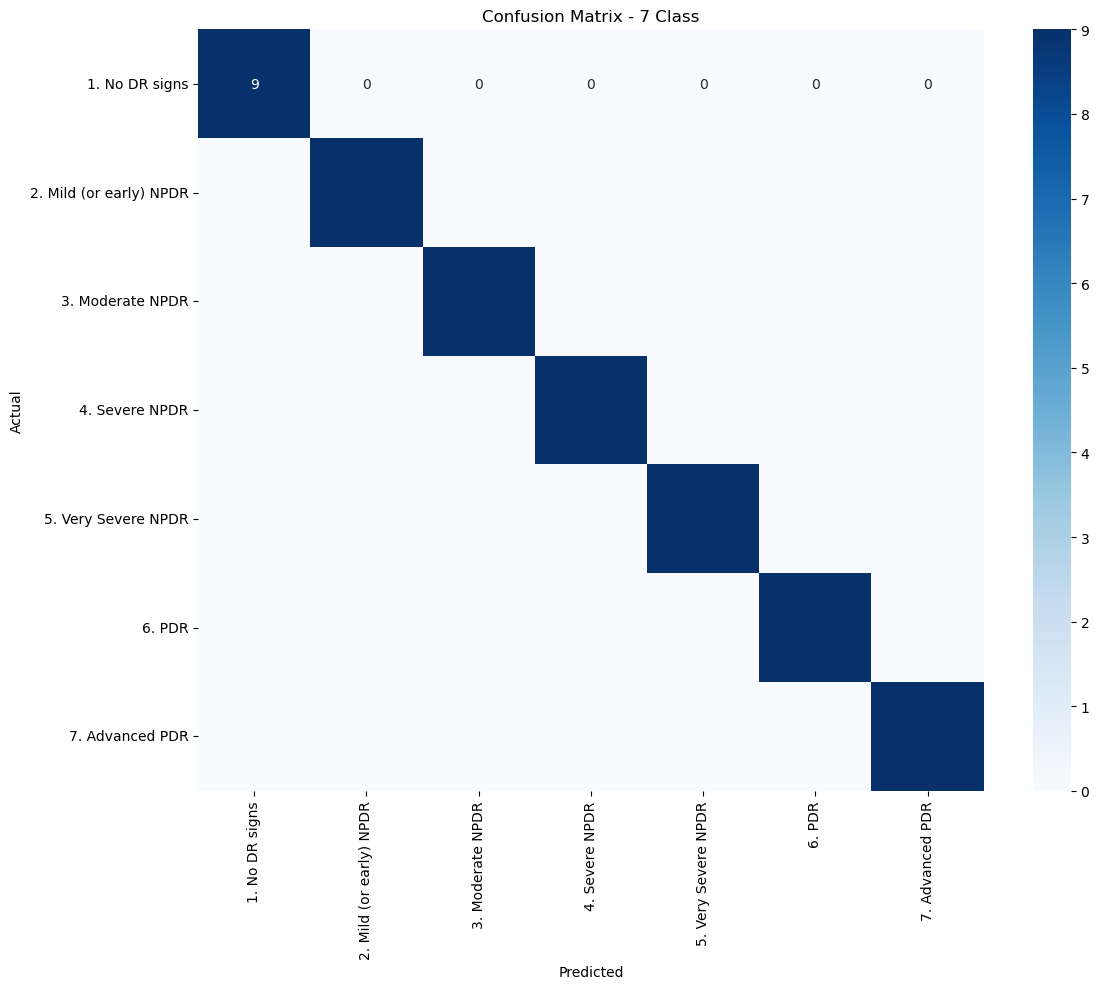


Generating ROC Curve...


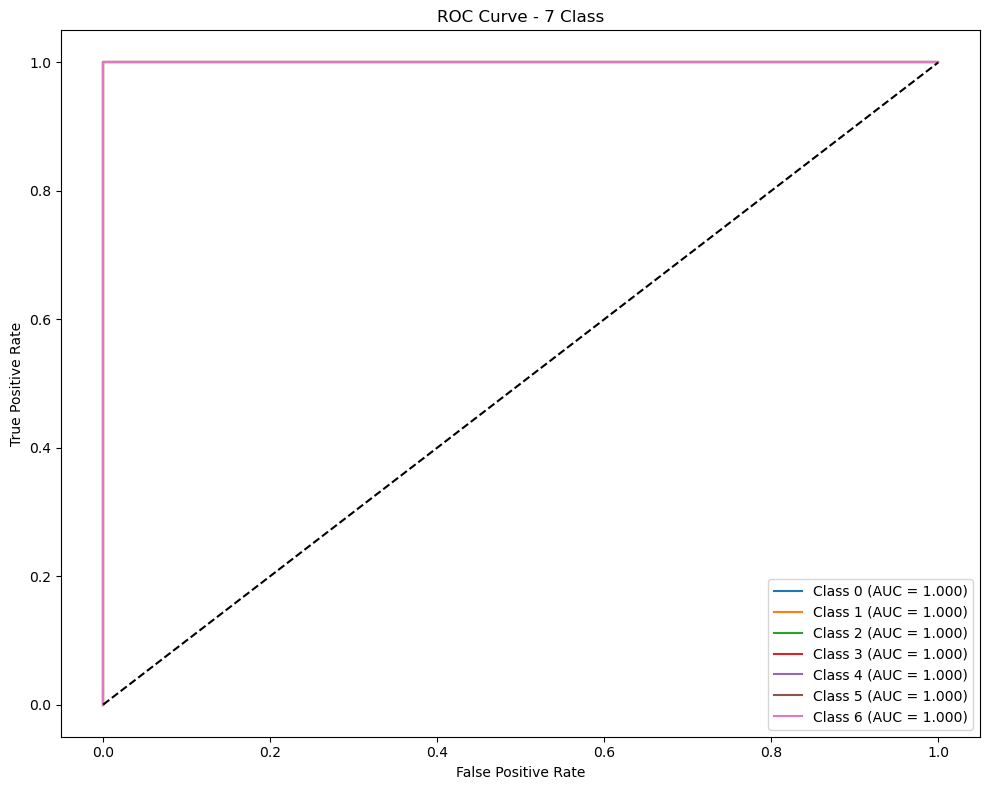

Generating Precision-Recall Curve...


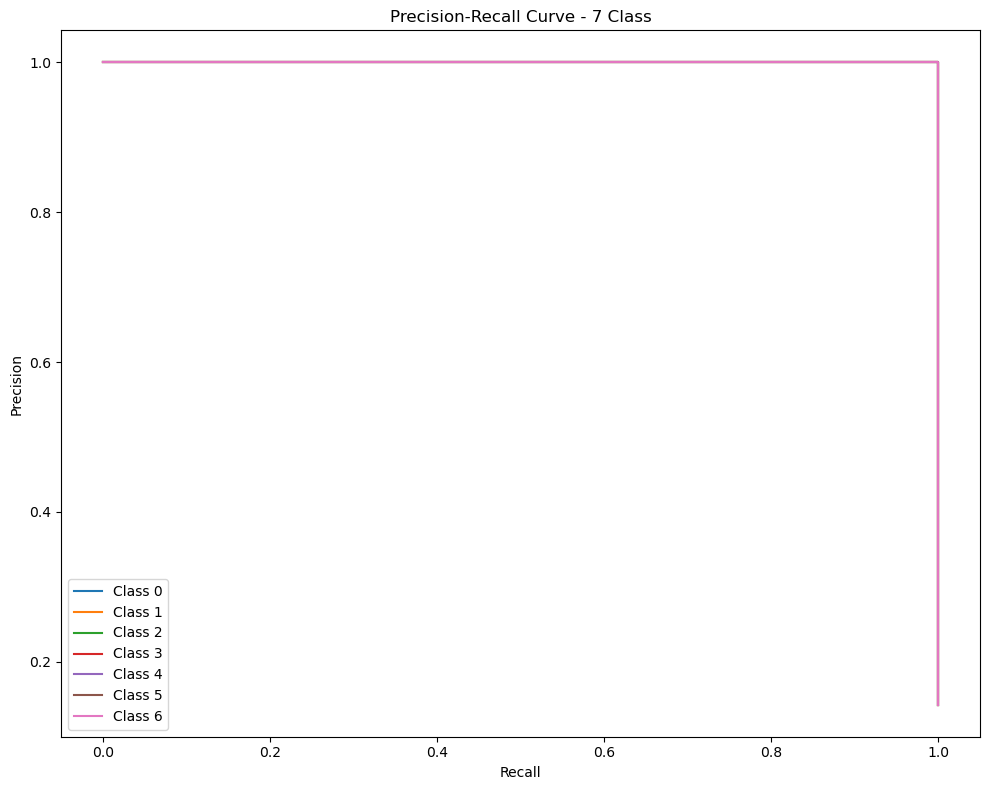

Generating Training Graphs...


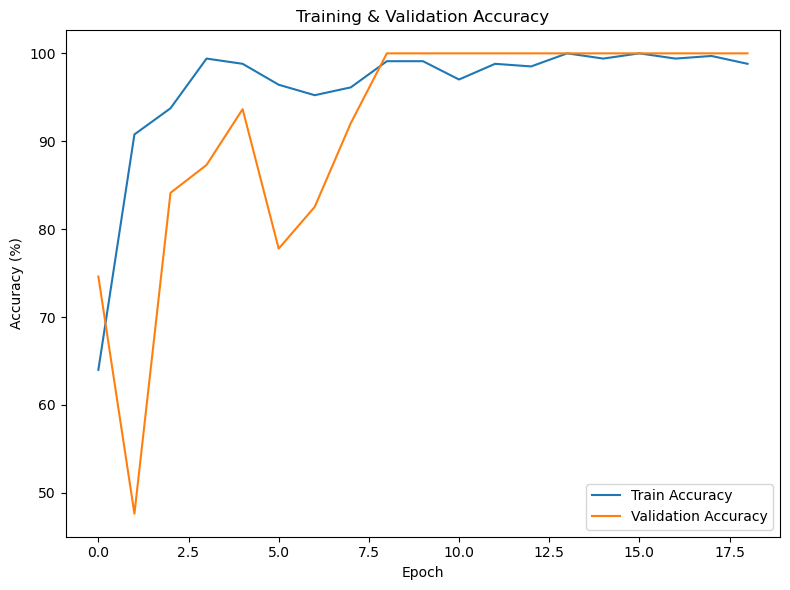

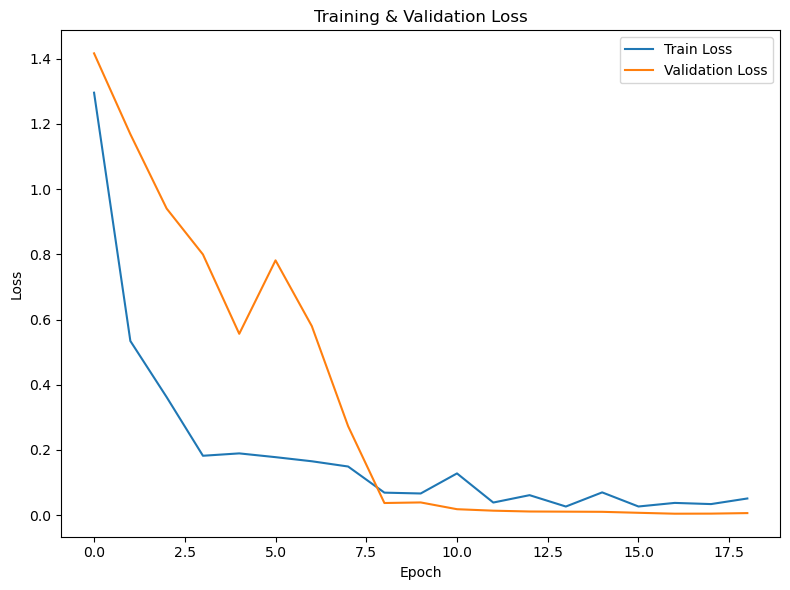


 ALL EVALUATION COMPLETED SUCCESSFULLY!


In [19]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve
)
from sklearn.preprocessing import label_binarize

print("\n" + "="*70)
print(" FINAL MODEL EVALUATION")
print("="*70)

# ---------------- LOAD BEST MODEL ----------------
model_path = 'best_model_7class.pth'

if not os.path.exists(model_path):
    raise FileNotFoundError(f"{model_path} not found!")

checkpoint = torch.load(model_path)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

print(f" Best Model Loaded (Val F1: {checkpoint['val_f1_macro']:.4f})")

# ---------------- GET PREDICTIONS ----------------
all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        _, predicted = outputs.max(1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs = np.array(all_probs)

# ---------------- CLASSIFICATION REPORT ----------------
print("\n Classification Report:")
print(classification_report(
    all_labels,
    all_preds,
    target_names=train_dataset.classes,
    zero_division=0
))

# ---------------- CONFUSION MATRIX ----------------
plt.figure(figsize=(12, 10))
cm = confusion_matrix(all_labels, all_preds)

sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=train_dataset.classes,
            yticklabels=train_dataset.classes)

plt.title('Confusion Matrix - 7 Class')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

# ---------------- ROC CURVE (7-Class) ----------------
print("\nGenerating ROC Curve...")

n_classes = 7
y_true_bin = label_binarize(all_labels, classes=range(n_classes))

plt.figure(figsize=(10, 8))

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], all_probs[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"Class {i} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - 7 Class")
plt.legend()
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=300)
plt.show()

# ---------------- PRECISION-RECALL CURVE ----------------
print("Generating Precision-Recall Curve...")

plt.figure(figsize=(10, 8))

for i in range(n_classes):
    precision, recall, _ = precision_recall_curve(
        y_true_bin[:, i],
        all_probs[:, i]
    )
    plt.plot(recall, precision, label=f"Class {i}")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - 7 Class")
plt.legend()
plt.tight_layout()
plt.savefig("precision_recall_curve.png", dpi=300)
plt.show()

# ---------------- TRAINING HISTORY PLOTS ----------------
print("Generating Training Graphs...")

# Accuracy Plot
plt.figure(figsize=(8, 6))
plt.plot(history['train_acc'], label='Train Accuracy')
plt.plot(history['val_acc'], label='Validation Accuracy')
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training & Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("accuracy_curve.png", dpi=300)
plt.show()

# Loss Plot
plt.figure(figsize=(8, 6))
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training & Validation Loss")
plt.legend()
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=300)
plt.show()

print("\n" + "="*70)
print(" ALL EVALUATION COMPLETED SUCCESSFULLY!")
print("="*70)
